# Validation & Evaluation Pipeline
- **Chiến lược:** Stratified 5-Fold Cross-Validation (phân phối gian lận ~1.670% đồng nhất giữa các fold, chống rò rỉ dữ liệu).
- **Metric chính:** AUPRC (Average Precision) và F1-Score kèm Optimal Decision Threshold.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

### 1. Phân phối nhãn & Cấu trúc dữ liệu

In [2]:
df_raw = pd.read_csv("train.csv")
print(f"Shape: {df_raw.shape}")
display(df_raw["is_fraud"].value_counts(normalize=True).mul(100).round(3).rename("Tỷ lệ %"))

Shape: (699960, 26)


is_fraud
0.0    98.33
1.0     1.67
Name: Tỷ lệ %, dtype: float64

### 2. Thiết lập Stratified 5-Fold & Xuất `train_folds.csv`

In [3]:
df_folds = df_raw.copy()
df_folds["fold"] = -1

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for fold, (_, val_idx) in enumerate(skf.split(df_folds, df_folds["is_fraud"])):
    df_folds.loc[val_idx, "fold"] = fold

df_folds["fold"] = df_folds["fold"].astype(int)
df_folds.to_csv("train_folds.csv", index=False)

display(df_folds.groupby("fold")["is_fraud"].agg(
    total="count",
    fraud_count="sum",
    fraud_rate=lambda x: f"{x.mean()*100:.3f}%"
))

,total,fraud_count,fraud_rate
fold,,,
0,139992,2337.0,1.669%
1,139992,2338.0,1.670%
2,139992,2338.0,1.670%
3,139992,2338.0,1.670%
4,139992,2338.0,1.670%


### 3. Module dùng chung: `validation_pipeline.py`

In [4]:
%%writefile validation_pipeline.py
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

def evaluate_fraud_predictions(y_true, y_pred_proba, verbose=True):
    y_true = np.asarray(y_true)
    y_pred_proba = np.asarray(y_pred_proba)
    
    auprc = average_precision_score(y_true, y_pred_proba)
    roc_auc = roc_auc_score(y_true, y_pred_proba)
    
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_pred_proba)
    f1_scores = np.divide(
        2 * (precisions * recalls),
        (precisions + recalls),
        out=np.zeros_like(precisions),
        where=(precisions + recalls) != 0
    )
    
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
    best_f1 = f1_scores[best_idx]
    f1_default = f1_score(y_true, (y_pred_proba >= 0.5).astype(int), zero_division=0)
    cm = confusion_matrix(y_true, (y_pred_proba >= best_threshold).astype(int))
    
    if verbose:
        print("=" * 50)
        print(f"AUPRC:          {auprc:.4f}")
        print(f"ROC-AUC:        {roc_auc:.4f}")
        print(f"F1 @ 0.50:      {f1_default:.4f}")
        print(f"Best Threshold: {best_threshold:.4f} => Best F1: {best_f1:.4f}")
        print(f"Confusion Matrix (Best Thresh):\n{cm}")
        print("=" * 50)
        
    return {
        "auprc": auprc,
        "roc_auc": roc_auc,
        "best_threshold": float(best_threshold),
        "best_f1": float(best_f1),
        "f1_default": float(f1_default),
        "confusion_matrix": cm
    }

def run_cv_pipeline(model_fn, feature_cols, data_path="train_folds.csv", n_splits=5, preprocess_fn=None):
    df = pd.read_csv(data_path)
    oof_predictions = np.zeros(len(df))
    fold_auprcs = []
    
    for fold in range(n_splits):
        train_mask = (df["fold"] != fold)
        val_mask = (df["fold"] == fold)
        
        X_train = df.loc[train_mask, feature_cols].copy()
        y_train = df.loc[train_mask, "is_fraud"].values
        X_val = df.loc[val_mask, feature_cols].copy()
        y_val = df.loc[val_mask, "is_fraud"].values
        
        if preprocess_fn is not None:
            X_train, y_train, X_val = preprocess_fn(X_train, y_train, X_val)
            
        model = model_fn()
        model.fit(X_train, y_train)
        
        val_preds = model.predict_proba(X_val)[:, 1]
        oof_predictions[val_mask] = val_preds
        
        fold_auprc = average_precision_score(y_val, val_preds)
        fold_auprcs.append(fold_auprc)
        print(f"Fold {fold} AUPRC: {fold_auprc:.4f}")
        
    print(f"\nMean AUPRC: {np.mean(fold_auprcs):.4f} +/- {np.std(fold_auprcs):.4f}")
    overall_metrics = evaluate_fraud_predictions(df["is_fraud"].values, oof_predictions, verbose=True)
    return oof_predictions, overall_metrics


Overwriting validation_pipeline.py


### 4. Kiểm thử Baseline Model (5-Fold CV)

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from validation_pipeline import run_cv_pipeline, evaluate_fraud_predictions

features = [
    "amount_usd", "hours_since_last_txn", "txn_count_last_24h",
    "merchant_risk_score", "cvv_retry_count"
]

def preprocess_inside_fold(X_tr, y_tr, X_va):
    scaler = StandardScaler()
    X_tr_s = pd.DataFrame(scaler.fit_transform(X_tr), columns=X_tr.columns, index=X_tr.index)
    X_va_s = pd.DataFrame(scaler.transform(X_va), columns=X_va.columns, index=X_va.index)
    return X_tr_s, y_tr, X_va_s

oof_preds, baseline_metrics = run_cv_pipeline(
    model_fn=lambda: LogisticRegression(class_weight="balanced", max_iter=200, random_state=42),
    feature_cols=features,
    data_path="train_folds.csv",
    n_splits=5,
    preprocess_fn=preprocess_inside_fold
)

Fold 0 AUPRC: 0.1928


Fold 1 AUPRC: 0.1971


Fold 2 AUPRC: 0.1956


Fold 3 AUPRC: 0.1872


Fold 4 AUPRC: 0.1839

Mean AUPRC: 0.1913 +/- 0.0050


AUPRC:          0.1909
ROC-AUC:        0.8510
F1 @ 0.50:      0.1124
Best Threshold: 0.8920 => Best F1: 0.2563
Confusion Matrix (Best Thresh):
[[675232  13039]
 [  8055   3634]]


### 5. Precision-Recall Curve & Optimal Threshold

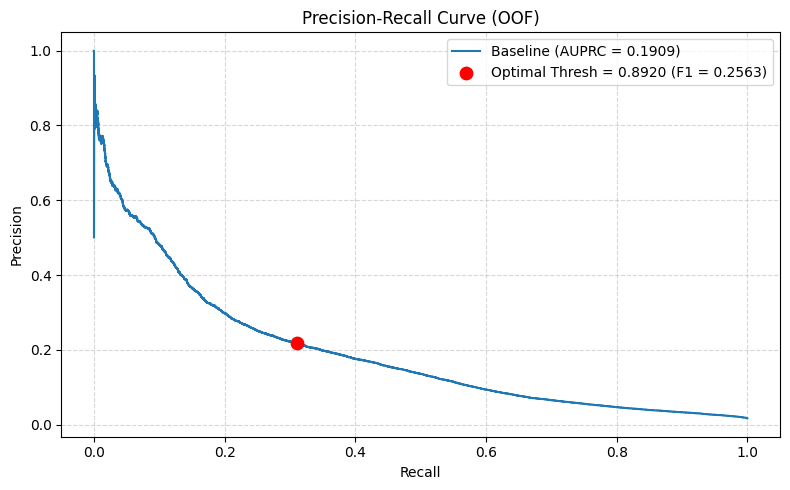

In [6]:
y_true = df_folds["is_fraud"].values
precisions, recalls, thresholds = precision_recall_curve(y_true, oof_preds)

plt.figure(figsize=(8, 5))
plt.plot(recalls, precisions, label=f"Baseline (AUPRC = {baseline_metrics['auprc']:.4f})")

best_th = baseline_metrics["best_threshold"]
idx_th = np.argmin(np.abs(thresholds - best_th))
plt.scatter(recalls[idx_th], precisions[idx_th], color="red", s=80, zorder=5,
            label=f"Optimal Thresh = {best_th:.4f} (F1 = {baseline_metrics['best_f1']:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (OOF)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()